# CatBoost

CatBoost (Categorical Boosting) is an open-source gradient boosting algorithm developed by Yandex. It is based on decision trees and uses boosting to combine multiple weak learners into a strong predictive model.

CatBoost introduces techniques such as Ordered Boosting and specialized categorical feature processing to reduce prediction bias and improve model generalization.

Unlike traditional gradient boosting algorithms, CatBoost can handle categorical features directly without requiring extensive manual encoding.

## Types of CatBoost Models

1. **CatBoostRegressor:** Used for predicting continuous numerical values.
2. **CatBoostClassifier:** Used for classification problems involving categorical target variables.

## Key Features

- Ordered Boosting to help reduce prediction bias.
- Native handling of categorical features.
- Effective performance on structured and tabular datasets.
- Regularization techniques to reduce overfitting.
- Support for classification and regression tasks.

## Advantages

- Strong predictive performance on tabular datasets.
- Handles categorical variables efficiently.
- Requires relatively little preprocessing.
- Supports feature importance analysis.
- Offers several regularization and tuning options.

## Limitations

- Can be computationally expensive with large datasets.
- Training time may increase with many iterations.
- Hyperparameter tuning can require considerable resources.

## Applications

- Customer churn prediction.
- Credit risk assessment.
- Sales and demand forecasting.
- Fraud detection.
- Medical data classification.
- House price prediction.

In [5]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve)
import warnings
warnings.filterwarnings('ignore')

In [6]:
# load dataset
housing = fetch_california_housing(as_frame=True)

housing_df = housing.frame.copy()

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [7]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [8]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [9]:
housing_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

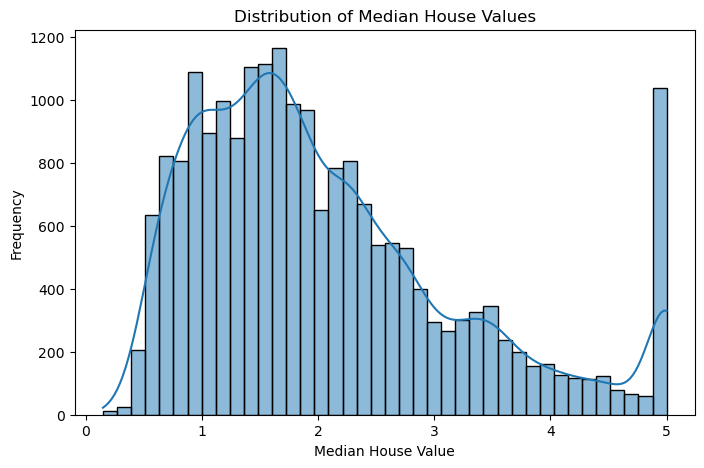

In [10]:
# target variable distribution
plt.figure(figsize=(8, 5))

sns.histplot(housing_df['MedHouseVal'],bins=40,kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

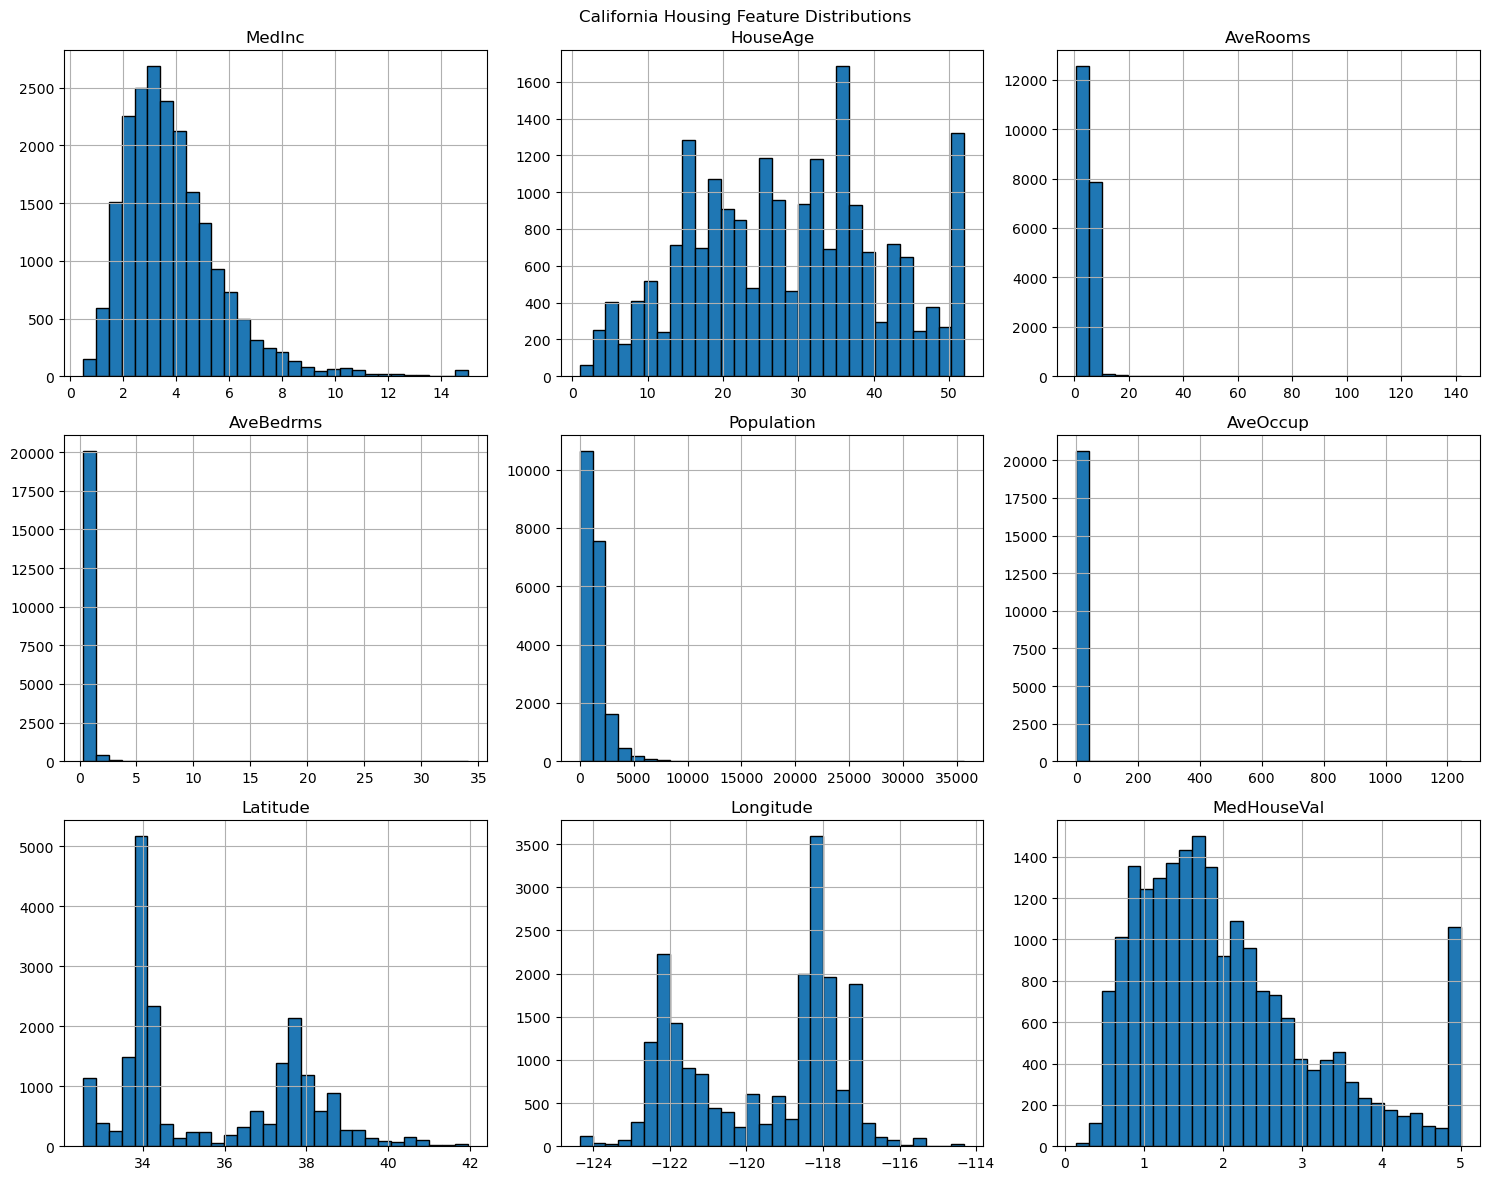

In [11]:
# feature distributions
housing_df.hist(figsize=(15, 12),bins=30,edgecolor='black')

plt.suptitle("California Housing Feature Distributions")
plt.tight_layout()
plt.show()

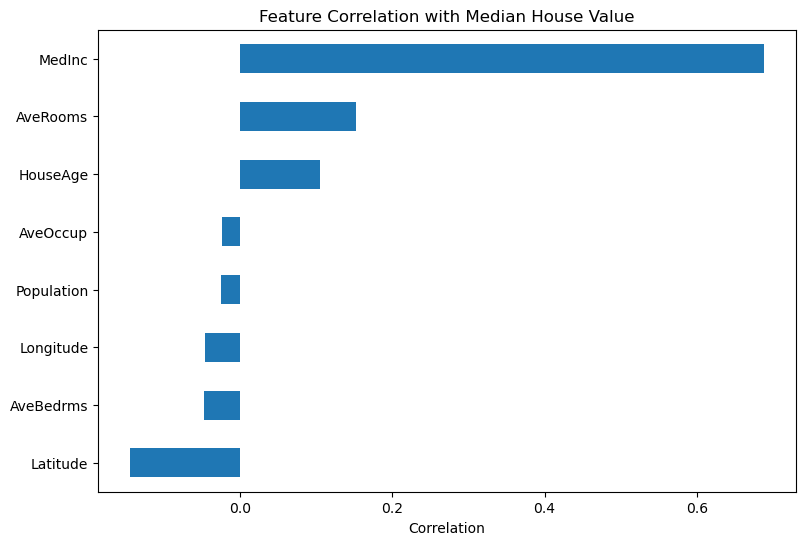

In [12]:
# feature rlship with target
target_corr = housing_df.corr()['MedHouseVal'].drop('MedHouseVal')

target_corr = target_corr.sort_values()

plt.figure(figsize=(9, 6))

target_corr.plot(kind='barh')

plt.title("Feature Correlation with Median House Value")
plt.xlabel("Correlation")
plt.show()

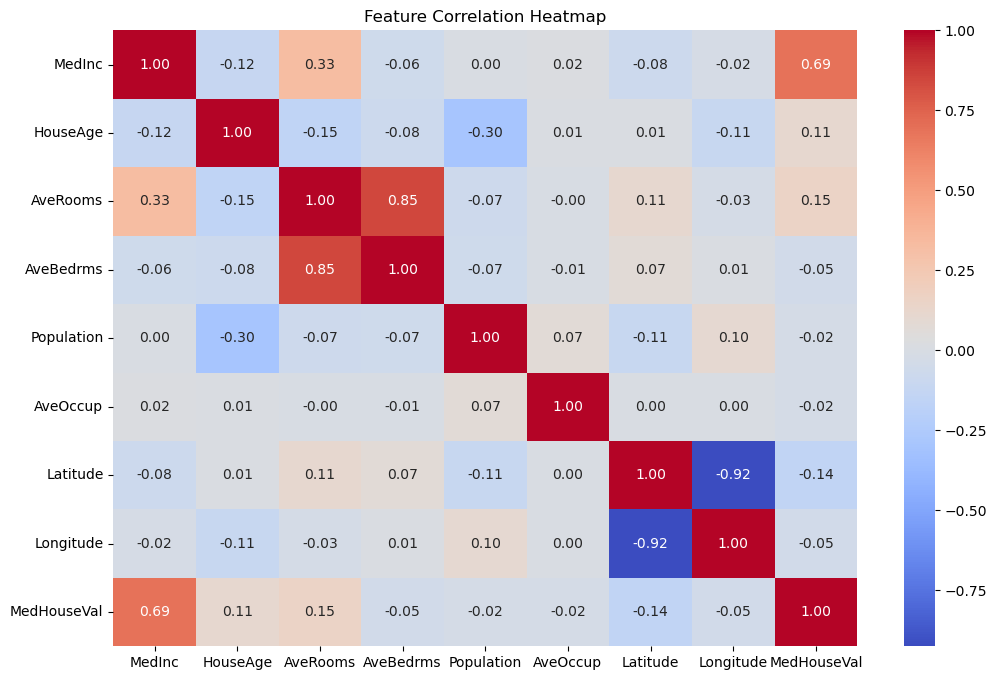

In [13]:
# correlation
plt.figure(figsize=(12, 8))

sns.heatmap(housing_df.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Feature Correlation Heatmap")
plt.show()

In [14]:
# Preprocessing
# separate features and targets
X = housing_df.drop('MedHouseVal', axis=1)
y = housing_df['MedHouseVal']

In [18]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Features:" ,X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [19]:
# Modelling
cat_reg = CatBoostRegressor(iterations=300,learning_rate=0.05,depth=6,loss_function='RMSE',random_seed=42,verbose=100,thread_count=2)

cat_reg.fit(X_train, y_train)

0:	learn: 1.1244518	total: 1.85s	remaining: 9m 13s
100:	learn: 0.5369823	total: 3.07s	remaining: 6.05s
200:	learn: 0.4900335	total: 4.16s	remaining: 2.05s
299:	learn: 0.4558204	total: 5.15s	remaining: 0us


CatBoostRegressor(depth=6, iterations=300, learning_rate=0.05, loss_function='RMSE', random_seed=42, thread_count=2, verbose=100)

In [20]:
# Predictions
y_train_pred = cat_reg.predict(X_train)
y_test_pred = cat_reg.predict(X_test)

In [21]:
# Evaluation
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)

print("\nTraining MSE:", train_mse)
print("Testing MSE:", test_mse)

print("\nTraining RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

print("\nTraining R2:", train_r2)
print("Testing R2:", test_r2)

Training MAE: 0.31433541569345014
Testing MAE: 0.33220235014875954

Training MSE: 0.20777221779623944
Testing MSE: 0.2429642904299602

Training RMSE: 0.45582037887334464
Testing RMSE: 0.4929140801701248

Training R2: 0.8445724085238395
Testing R2: 0.8145889608020568


In [22]:
# Actual vs predicted
cat_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_test_pred
})

cat_results.head(10)

,Actual Values,Predicted Values
0,0.47700,0.534497
1,0.45800,1.116741
2,5.00001,4.572433
3,2.18600,2.473023
4,2.78000,2.376508
5,1.58700,1.623809
6,1.98200,2.355542
7,1.57500,1.612018
8,3.40000,2.932218
9,4.46600,4.620049


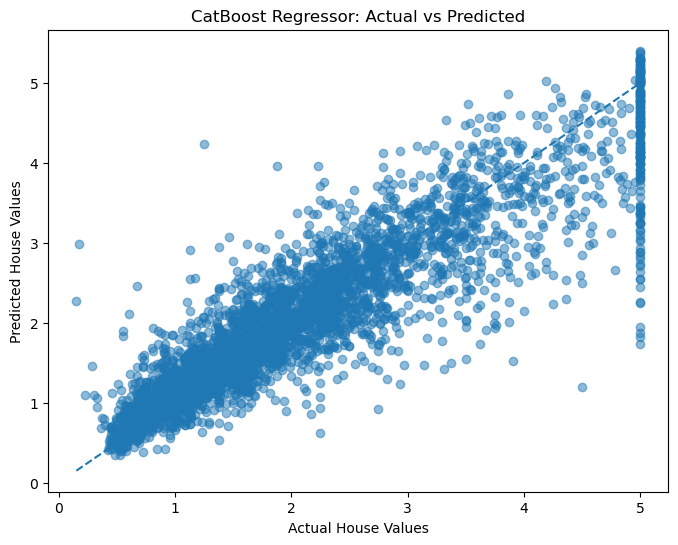

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("CatBoost Regressor: Actual vs Predicted")

plt.show()

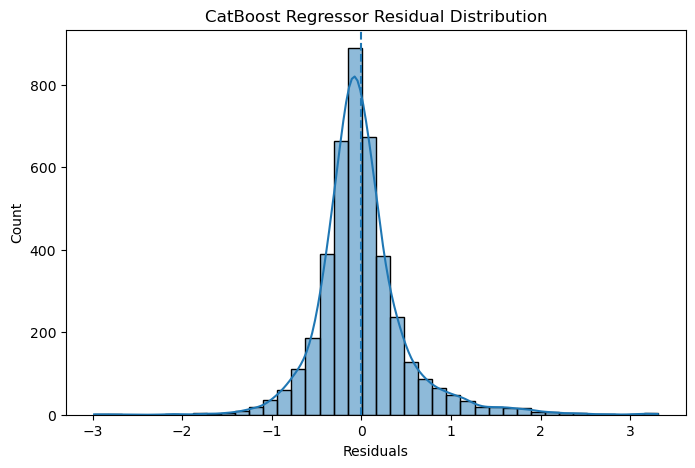

In [24]:
# Residual distribution
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=40, kde=True)

plt.axvline(0, linestyle='--')

plt.title("CatBoost Regressor Residual Distribution")
plt.xlabel("Residuals")
plt.show()

In [25]:
# feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cat_reg.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance

,Feature,Importance
0,MedInc,36.079390
6,Latitude,21.159986
7,Longitude,18.447271
5,AveOccup,15.203773
1,HouseAge,4.814835
2,AveRooms,2.342279
3,AveBedrms,1.013285
4,Population,0.939182


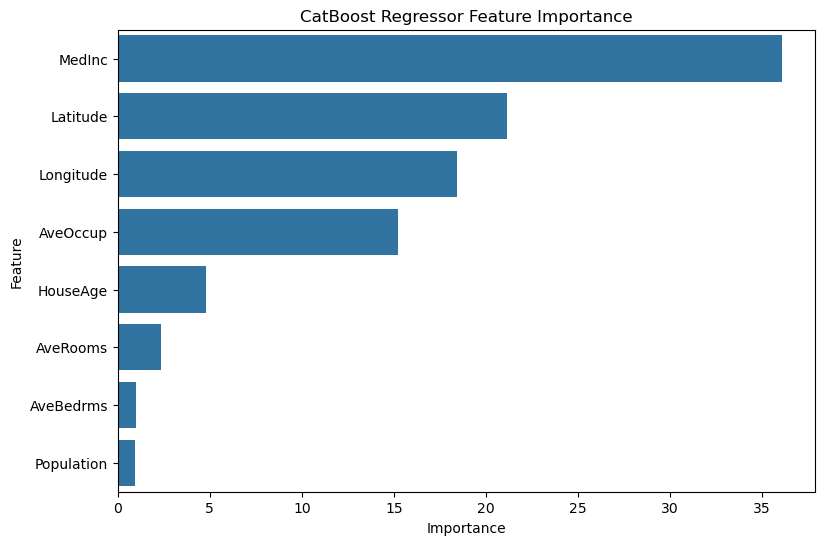

In [26]:
plt.figure(figsize=(9, 6))

sns.barplot(data=feature_importance,x='Importance',y='Feature')

plt.title("CatBoost Regressor Feature Importance")
plt.show()

In [28]:
# Hyperparameter tuning
cat_param_grid = {
    'iterations': [200, 300],
    'depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'l2_leaf_reg': [3, 5]
}
# GridSearch
cat_grid = GridSearchCV(
    estimator=CatBoostRegressor(loss_function='RMSE',random_seed=42,verbose=0,thread_count=2),param_grid=cat_param_grid,cv=3,scoring='neg_mean_squared_error',n_jobs=1,
    verbose=1
)
# fit gridsearch
cat_grid.fit(X_train, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


,estimator,"CatBoostRegre...=2, verbose=0)"
,param_grid,"{'depth': [4, 6, ...], 'iterations': [200, 300], 'l2_leaf_reg': [3, 5], 'learning_rate': [0.03, 0.05, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False


In [29]:
print("Best Parameters:", cat_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-cat_grid.best_score_))

Best Parameters: {'depth': 8, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
Best CV RMSE: 0.46157917223191985


In [30]:
# tuned predictions
print("Best Parameters:", cat_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-cat_grid.best_score_))

Best Parameters: {'depth': 8, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
Best CV RMSE: 0.46157917223191985


In [31]:
# tuned evaluation
tuned_mae = mean_absolute_error(y_test, y_tuned_pred)
tuned_mse = mean_squared_error(y_test, y_tuned_pred)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_tuned_pred)

print("Tuned Training R2:", r2_score(y_train, y_tuned_train_pred))
print("Tuned Testing MAE:", tuned_mae)
print("Tuned Testing MSE:", tuned_mse)
print("Tuned Testing RMSE:", tuned_rmse)
print("Tuned Testing R2:", tuned_r2)

NameError: name 'y_tuned_pred' is not defined

In [ ]:
# comparison
cat_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Baseline': [test_mae,test_mse,test_rmse,test_r2
    ],
    'Tuned': [tuned_mae,tuned_mse,tuned_rmse,tuned_r2
    ]
})

cat_comparison

In [ ]:
cat_comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6))

plt.title("Baseline vs Tuned CatBoost Regressor")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## Classification

In [ ]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

cancer_df['target'] = cancer.target

print(cancer_df
cancer_df.head()